# Video Game Analysis-Section 1: Analysis of Video Game Data to Find Relationship Between Console and US Sales

## Introduction


### Analysis of Video Game Data to Find Relationship Between Console and Sales

Since video games were a crucial part of socializing in my childhood, I wanted to analyze the trends of video games from that era. With the peak of video games being released from 2004-2010, including legendary games such as Minecraft, we wanted to conduct a scientific visualization and analysis approach to determine interesting trends, patterns, and conclusions we can derive. I am hoping that this will enlighten us to (potential) irregularities in the data, providing me a more comprehensive understanding of video game patterns.

I want to find the relationship between the Console and the amount of US Sales.

This research question is important for us to answer because it will help us determine a variety of factors. First of course, is how successful the console is. A console that has more sales means that more people want to buy it, either because of product quality, customer satisfaction, etc. We can then use this to determine the "most sold console" in that time frame, and also use it to determine future purchases if we are looking to buy a new console in the future. If a company like Nintendo releases one versus one like Sony, the company that has had more sales in the past might be more indicative of having a successful, stronger product in the future.

In [115]:
import pandas as pd                  
import matplotlib.pyplot as plt        
import seaborn as sns; sns.set()
import numpy as np
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split


In [116]:
df = pd.read_csv("video_games copy.csv", encoding = 'unicode-escape')
df

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
0,Nintendo DS,Super Mario 64 DS,4.69,1,1,1,1,2004,1,0,...,0,0,0,0,0,1,0,0,0,1
1,Sony PSP,Lumines: Puzzle Fusion,0.56,0,0,0,1,2004,1,0,...,0,0,0,0,0,0,0,0,0,0
2,Nintendo DS,WarioWare Touched!,0.54,0,0,0,1,2004,1,0,...,0,0,0,0,0,1,1,1,1,1
3,Sony PSP,Hot Shots Golf: Open Tee,0.49,0,0,0,0,2004,1,0,...,0,0,0,0,0,0,0,0,0,1
4,Nintendo DS,Spider-Man 2,0.45,0,0,0,0,2004,1,0,...,0,0,0,0,0,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1765,PlayStation 3,MotoGP 09/10,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,1,0,0,0,0,1
1766,PlayStation 3,Prison Break: The Conspiracy,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1767,Nintendo Wii,"Sakura Wars: So Long, My Love",0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1768,X360,Record of Agarest War (The Really Naughty Limi...,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,1,0,0,0


In [117]:
df.shape

(1770, 166)

## Dataset Cleaning 

In [118]:
df.isna().sum()

Console                0
Title                  0
US Sales (millions)    0
Block4                 0
Block2                 0
                      ..
Platform               0
Isometric              0
SideScrolling          0
TopDown                0
ThirdPerson            0
Length: 166, dtype: int64

I found that there are no missing values in the data that are automatically detected. The two variables of interest, Console and US Sales, do not have any values listed as N/A. Since there are no automatically missing variables, I will not be dropping any values. I also noticed that the values of 1 and 0 under many of the columns seem to indicate yes or no to having certain video game features, and we will not be dropping any of these values.

Next, I want to see if there are any uncommon values in the US Sales column.

In [119]:
df["US Sales (millions)"].describe()

count    1770.000000
mean        0.479785
std         1.064915
min         0.010000
25%         0.090000
50%         0.190000
75%         0.450000
max        14.660000
Name: US Sales (millions), dtype: float64

<Axes: >

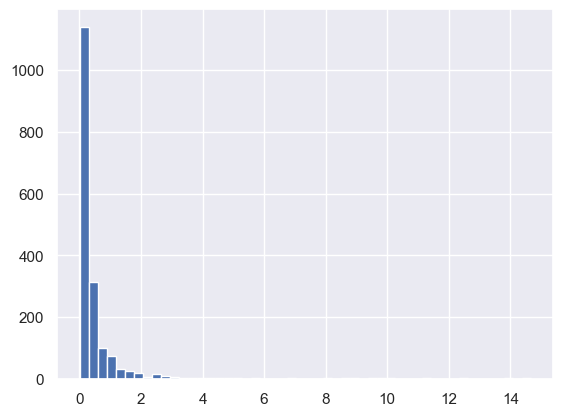

In [120]:
df["US Sales (millions)"].hist(bins=50)

I can see that the data seems to be skewed right with a few games having a lot more sales than the rest of them. The mean of 0.47 million sales is different than the median of 0.19 million sales, which makes me think that there are certain data points that skew the data.

In [121]:
df.nlargest(20, "US Sales (millions)")

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
173,Nintendo Wii,Wii Play,14.66,1,1,1,1,2006,0,0,...,0,0,0,0,1,0,0,0,0,1
1376,Nintendo Wii,Wii Sports Resort,13.87,1,1,1,1,2009,0,0,...,0,0,1,0,0,0,0,0,0,1
932,Nintendo Wii,Mario Kart Wii,12.39,1,1,1,1,2008,0,0,...,0,0,0,0,0,0,0,0,0,1
1377,Nintendo Wii,New Super Mario Bros. Wii,11.35,1,1,1,1,2009,0,0,...,0,0,0,0,0,1,0,1,0,1
174,Nintendo DS,New Super Mario Bros.,10.03,1,1,1,1,2006,0,0,...,0,0,0,0,0,1,0,1,0,0
23,Nintendo DS,Mario Kart DS,9.99,1,1,1,1,2005,0,1,...,0,0,0,0,0,0,0,0,0,1
24,Nintendo DS,Nintendogs,9.72,1,1,1,1,2005,0,1,...,0,0,0,0,0,0,0,0,0,1
467,Nintendo Wii,Wii Fit,9.60,1,1,1,1,2007,0,0,...,0,0,0,0,0,0,0,0,0,1
1378,Nintendo Wii,Wii Fit Plus,9.06,1,1,1,1,2009,0,0,...,0,0,0,0,0,0,0,0,0,1
1379,X360,Call of Duty: Modern Warfare 2,8.61,1,1,1,1,2009,0,0,...,0,0,0,0,1,0,0,0,0,0


After looking at the 20 highest values for US Sales, some of the most popular games listed are Wii Play (at 14.66M) and Mario Kart Wii (at 12.39M). Since these values seem accurate, I will not be removing any of them. Removing these values would eliminate the most well known games in the dataset and distort the  relationship between Console and US Sales. There were also no impossible values of negative or zero sales within the data, with all games making a profit of at least the minimum value of 0.01 million USD. The right-skewed distribution also does not worry us since it is expected in the video game industry to have a small number of popular games that outsell majority of games.

In [122]:
df_console=df.Console.value_counts()
df_console

Console
X360             437
Nintendo DS      418
PlayStation 3    312
Sony PSP         307
Nintendo Wii     296
Name: count, dtype: int64

All five consoles (X360, Nintendo DS, PlayStation 3, Sony PSP, Nintendo Wii) each appear between 296 and 437 times in the dataset. No console qualifies as uncommon, so no grouping or collapsing of categories was necessary.

## Summarizing Data

#### What is the relationship between game consle and US Sales (millions) in this dataset?

In [123]:
df_describe_relationship=df.groupby("Console")["US Sales (millions)"].describe().reset_index()
df_describe_relationship

,Console,count,mean,std,min,25%,50%,75%,max
0,Nintendo DS,418.0,0.447943,1.121021,0.01,0.06,0.12,0.3275,10.03
1,Nintendo Wii,296.0,0.691115,1.775619,0.01,0.10,0.26,0.4800,14.66
2,PlayStation 3,312.0,0.457564,0.588260,0.02,0.12,0.27,0.5225,4.95
3,Sony PSP,307.0,0.240326,0.339833,0.01,0.05,0.13,0.2800,2.97
4,X360,437.0,0.551190,0.927919,0.01,0.12,0.24,0.5200,8.61


In [124]:
df_medians=df.groupby("Console")["US Sales (millions)"].median().reset_index()
df_medians

,Console,US Sales (millions)
0,Nintendo DS,0.12
1,Nintendo Wii,0.26
2,PlayStation 3,0.27
3,Sony PSP,0.13
4,X360,0.24


In [125]:
df_means=df.groupby("Console")["US Sales (millions)"].mean().reset_index()
df_means

,Console,US Sales (millions)
0,Nintendo DS,0.447943
1,Nintendo Wii,0.691115
2,PlayStation 3,0.457564
3,Sony PSP,0.240326
4,X360,0.551190


<Axes: title={'center': 'Mean US Sales (millions) by Console'}, xlabel='Console'>

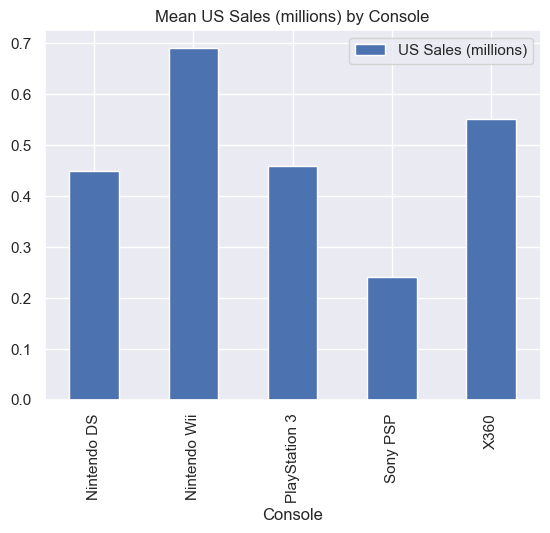

In [126]:
df_means.plot(kind="bar", x="Console", y="US Sales (millions)", title="Mean US Sales (millions) by Console")

<Axes: title={'center': 'Median US Sales (millions) by Console'}, xlabel='Console'>

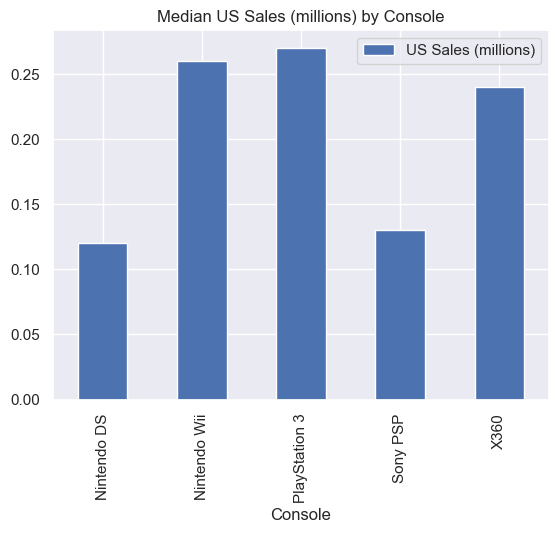

In [127]:
df_medians.plot(kind="bar", x="Console", y="US Sales (millions)", title="Median US Sales (millions) by Console")

I calculated count, mean, median, standard deviation, minimum, Q1, Q3, and maximum US Sales in millions grouped by Console. I then made two bar charts using the mean sales and the median sales values of each console and displayed them above.

### Results

The results for both plots suggest there is a relationship between console and US Sales in this dataset. Nintendo Wii and X360 games tended to sell more in the US than games on other platforms. Sony PSP and Nintendo DS games tended to sell the least. 

The biggest difference I see between these two bar charts is that PlayStation 3 games had comparatively less sales when comparing means but comparatively more sales when comparing medians. Since the difference between mean and median sales is less for PlayStation 3, I can assume that this console tends to have more players across many games rather than having just a few hit games in the US.

All Console's distributions are right-skewed due to their means being larger than their medians, and they all have large standard deviations. This makes me believe that the difference between consoles is largely due to a small number of high selling games rather than consistent performance across all games on that platform. The boxplot below helps visualize the amount of higher outliers within the entire dataframe, putting into perspective how right skewed the entire distribution is.

These results show that there is a relationship between Console and US Sales (millions). I decided to draw this conclusion from the median amount of sales from each console since the data has many outliers and is skewed right. From the median sales, Nintendo Wii, PlayStation 3 and X360 make more in US Sales and are more popular than Nintendo DS and Sony PSP. 

## Conclusion

For this project I analyzed the relationship between our two variables of interest, Console, a categorical variable with five levels (Nintendo Wii, Nintendo DS, PlayStation 3, Sony PSP, and X360), and US Sales (millions), a quantitative variable measuring each game's US sales in millions of dollars. 

During data cleaning, I found no explicit or implicit missing values in either variable of interest, and no duplicate rows were present in the dataset. The US Sales distribution was found to be heavily right-skewed, but we did not remove any data since they represent legitimate blockbuster titles such as Wii Play (14.66M) and Mario Kart Wii (12.39M). No observations were dropped throughout the cleaning process. To answer our research question, we generated a boxplot and bar charts comparing sales distributions across consoles.

Overall, the analysis suggests a clear relationship between console type and U.S. video game sales. The comparisons indicate that Nintendo Wii and Xbox 360 games generally achieved higher sales levels relative to other platforms, while Sony PSP and Nintendo DS titles tended to perform worse in the U.S. market. Additionally, differences between mean and median sales highlighted variation in performance across consoles. For example, PlayStation 3 showed relatively higher median sales compared to its mean, suggesting sales were more evenly distributed rather than  concentrated to a few blockbuster games. Across all consoles, right-skewed distributions and large standard deviations indicate that sales performance is strongly influenced by a limited number of highly successful titles rather than consistent performance across all games.

One limitation of this analysis is that the dataset doesn't account for factors that may influence sales outcomes, such as release year, game genre, marketing investment, or installed console base. Leaving out these variables may distort the observed relationship between console and sales, meaning that console type alone may not fully explain differences in performance.

# Video Game Analysis-Section 2: Analysis of Video Game Review Scores and Sequel Status Using Statistical Inference

## Introduction

### Analysis of Video Game Review Scores and Sequel Status Using Statistical Inference

The dataset used in this analysis contains information on video games released between 2004 and 2010, including variables such as review scores and whether a game is a sequel or not. The population is listed under "df."

I then cleaned the population dataset, and then from this cleaned larger population dataset, a random sample of 200 video games was drawn to conduct our statistical analyses, allowing me to make inferences about the broader population of video games released during this time period.

Populations and Samples: This dataset represents the population of video games released between 2004 and 2010. The population of interest is all video games released during this time frame. Since the data represents the total population rather than a sample, I decided to take a random sample of 200 games to use for our analyses.

#### Research Questions: 

I have 2 research questions regarding the logical variable, Sequel, that were answered in Part 2:

What proportion of video games in the random sample of 200 are sequels? What is a range of reasonable values for the proportion of video games released between 2004 to 2010 that are sequels?


We have research questions regarding the quantitative variable, Review Score, that we answered in Part 3:

What are some summary measures of the review score variable in the sample dataset? Is there evidence that the true mean review score of all video games released between 2004 and 2010 differs from 70, a common benchmark for an average game?

#### Contextual Importance: 
Understanding the proportion of video game sequels and the distribution of review scores is valuable for a variety of people across the gaming industry. For example, a video game publisher or studio executive who is deciding whether or not to move forward with a sequel versus an original title can use the data collected from this analysis to better understand how common sequels are in the market and whether they tend to perform differently in terms of critical reception. If sequels make up a substantial portion of releases but do not score significantly higher than average, that could inform a studio's strategy toward investing more in original intellectual property. Moreover, a gaming journalist or market analyst tracking gaming industry trends over time could use these findings as a baseline for comparing how frequency and review score distributions have shifted in recent years.

In [128]:
df

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
0,Nintendo DS,Super Mario 64 DS,4.69,1,1,1,1,2004,1,0,...,0,0,0,0,0,1,0,0,0,1
1,Sony PSP,Lumines: Puzzle Fusion,0.56,0,0,0,1,2004,1,0,...,0,0,0,0,0,0,0,0,0,0
2,Nintendo DS,WarioWare Touched!,0.54,0,0,0,1,2004,1,0,...,0,0,0,0,0,1,1,1,1,1
3,Sony PSP,Hot Shots Golf: Open Tee,0.49,0,0,0,0,2004,1,0,...,0,0,0,0,0,0,0,0,0,1
4,Nintendo DS,Spider-Man 2,0.45,0,0,0,0,2004,1,0,...,0,0,0,0,0,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1765,PlayStation 3,MotoGP 09/10,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,1,0,0,0,0,1
1766,PlayStation 3,Prison Break: The Conspiracy,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1767,Nintendo Wii,"Sakura Wars: So Long, My Love",0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1768,X360,Record of Agarest War (The Really Naughty Limi...,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,1,0,0,0


## Confidence Interval Analytical Tasks

### Research Question

I have 2 research questions regarding the logical variable, Sequal, that we want to answer:

What proportion of video games in the random sample of 200 are sequels? 

What is the range of reasonable values for the proportion of video games released between 2004 to 2010 that are sequels?

### Dataset Cleaning

In [129]:
df.isna().sum()

Console                0
Title                  0
US Sales (millions)    0
Block4                 0
Block2                 0
                      ..
Platform               0
Isometric              0
SideScrolling          0
TopDown                0
ThirdPerson            0
Length: 166, dtype: int64

In [130]:
df.Sequel.isna().sum()

np.int64(0)

In [131]:
df["Sequel"].value_counts()

Sequel
1    920
0    843
2      7
Name: count, dtype: int64

In [132]:
df[df["Sequel"]==2]

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
724,X360,The Elder Scrolls IV: Shivering Isles,0.18,0,0,0,0,2007,0,0,...,0,0,0,0,1,0,0,0,0,1
725,X360,Final Fantasy XI: Wings of the Goddess,0.18,0,0,0,0,2007,0,0,...,0,0,0,0,0,0,0,0,0,1
1158,X360,AC/DC Live: Rock Band - Track Pack,0.19,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,0,0,1
1161,PlayStation 3,AC/DC Live: Rock Band - Track Pack,0.19,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,0,0,1
1228,X360,Rock Band: Track Pack - Volume 2,0.10,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,0,0,1
1729,X360,Dragon Age: Origins - Awakening,0.24,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1734,PlayStation 3,Dragon Age: Origins - Awakening,0.19,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1


In [133]:
df_clean=df[df["Sequel"]!=2]
df_clean.Sequel.value_counts()

Sequel
1    920
0    843
Name: count, dtype: int64

I first want to clean the entire dataframe, or information about the population before we take any samples. We found that there are no missing values in the data that are automatically detected. The first variable of interest, Sequel, does not have any values listed as N/A. I also noticed that the values of 1 and 0 under many of the columns, including Sequel, seem to indicate yes or no answers to having certain video game features, and I will not be dropping any of these values since these are logical variables.

However, there were 7 value recorded as 2 under the Sequel column. I think that these inputs may have been a mistake since it does not fall under the logical variables 0 or 1, so I decided to drop them.

### Descriptive Analytics

In [134]:
df_sample=df_clean.sample(n=200)
df_sample

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
1276,X360,Blitz: The League II,0.07,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,0,0,1
751,Nintendo DS,Dementium: The Ward,0.15,0,0,0,0,2007,0,0,...,0,0,0,0,1,0,0,0,0,0
1257,Nintendo DS,Spider-Man: Web of Shadows,0.09,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,1,0,0
295,Sony PSP,Tiger Woods PGA Tour 07,0.21,0,0,0,0,2006,0,0,...,0,0,0,0,0,0,0,0,0,1
628,X360,FIFA Soccer 08,0.33,0,0,0,0,2007,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179,Nintendo DS,Cooking Mama,2.90,0,1,1,1,2006,0,0,...,0,0,0,0,1,0,0,0,0,0
862,Nintendo DS,Retro Game Challenge,0.05,0,0,0,0,2007,0,0,...,0,0,0,0,0,1,0,1,1,1
1566,Nintendo DS,Marvel Ultimate Alliance 2,0.14,0,0,0,0,2009,0,0,...,0,0,0,0,0,0,0,0,0,1
720,PlayStation 3,Enchanted Arms,0.18,0,0,0,0,2007,0,0,...,0,0,0,0,0,0,0,0,0,1


In [135]:
df_sample.shape

(200, 166)

In [136]:
df_sample["Sequel"].value_counts()

Sequel
1    102
0     98
Name: count, dtype: int64

In [137]:
len(df_sample[df_sample["Sequel"]==1])/len(df_sample)

0.51

The sample size is 200 rows from the original dataframe, randomly sampled. Since Sequel is a logical variable, the numeric summary used was proportion. From the sample of 200 video games, 101 of them are sequels. This means that 50.5% of games in the sample, or about half, are sequels to a previously released game.

### Confidence Interval

We are 95% confident that the true proportion of video games released between 2004 and 2010 that are sequels is between 0.435 and 0.575.

In [138]:
data=[]
for i in range (5000):
    sample = df_sample["Sequel"].sample(n=200, replace= True)
    data.append(sample.mean())
pd.DataFrame(data)

,0
0,0.530
1,0.520
2,0.545
3,0.595
4,0.550
...,...
4995,0.485
4996,0.520
4997,0.590
4998,0.550


In [139]:
interval_lower=np.percentile(data,2.5)
interval_upper=np.percentile(data,97.5)
print({interval_lower,interval_upper})


{np.float64(0.44), np.float64(0.58)}


## Hypothesis Testing Analytical Tasks

### Research Question

What are some summary measures of the review score variable in the sample dataset? 

Is there evidence that the true mean review score of all video games released between 2004 and 2010 differs from 70, a common benchmark for an average game?

### Dataset Cleaning

In part 2, the population data (df) was already cleaned and labeled as df_clean. I also have a sample of 200 rows from the cleaned population dataset labeled as df_sample. Just to to check again, we looked at the value counts, min, and max for the df variable again and found that none of the values look unnatural since all the review scores are between 1 and 100.

In [140]:
df["Review Score"].value_counts()

Review Score
72    62
73    61
75    60
70    56
80    56
      ..
97     1
20     1
32     1
26     1
17     1
Name: count, Length: 77, dtype: int64

In [141]:
df["Review Score"].describe()

count    1770.000000
mean       68.428814
std        13.894937
min        12.000000
25%        60.000000
50%        70.000000
75%        79.000000
max        98.000000
Name: Review Score, dtype: float64

In [142]:
df_sample

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
1276,X360,Blitz: The League II,0.07,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,0,0,1
751,Nintendo DS,Dementium: The Ward,0.15,0,0,0,0,2007,0,0,...,0,0,0,0,1,0,0,0,0,0
1257,Nintendo DS,Spider-Man: Web of Shadows,0.09,0,0,0,0,2008,0,0,...,0,0,0,0,0,0,0,1,0,0
295,Sony PSP,Tiger Woods PGA Tour 07,0.21,0,0,0,0,2006,0,0,...,0,0,0,0,0,0,0,0,0,1
628,X360,FIFA Soccer 08,0.33,0,0,0,0,2007,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179,Nintendo DS,Cooking Mama,2.90,0,1,1,1,2006,0,0,...,0,0,0,0,1,0,0,0,0,0
862,Nintendo DS,Retro Game Challenge,0.05,0,0,0,0,2007,0,0,...,0,0,0,0,0,1,0,1,1,1
1566,Nintendo DS,Marvel Ultimate Alliance 2,0.14,0,0,0,0,2009,0,0,...,0,0,0,0,0,0,0,0,0,1
720,PlayStation 3,Enchanted Arms,0.18,0,0,0,0,2007,0,0,...,0,0,0,0,0,0,0,0,0,1


## Descriptive Analysis

In [143]:
df_sample["Review Score"].value_counts()

Review Score
67    8
73    8
59    7
84    7
70    7
55    7
72    6
82    6
80    6
71    6
66    6
76    6
65    6
77    5
78    5
64    5
56    5
74    5
60    5
81    5
75    5
62    5
68    4
83    4
49    4
79    4
46    3
86    3
52    3
69    3
94    3
45    3
89    2
90    2
87    2
38    2
53    2
88    2
51    2
63    2
40    2
61    2
50    2
58    1
54    1
98    1
34    1
85    1
19    1
92    1
47    1
37    1
43    1
27    1
96    1
95    1
Name: count, dtype: int64

In [144]:
df_sample["Review Score"].describe()

count    200.000000
mean      68.500000
std       13.980604
min       19.000000
25%       59.750000
50%       70.000000
75%       79.000000
max       98.000000
Name: Review Score, dtype: float64

Text(0.5, 1.0, 'Distribution of Review Scores in Sample')

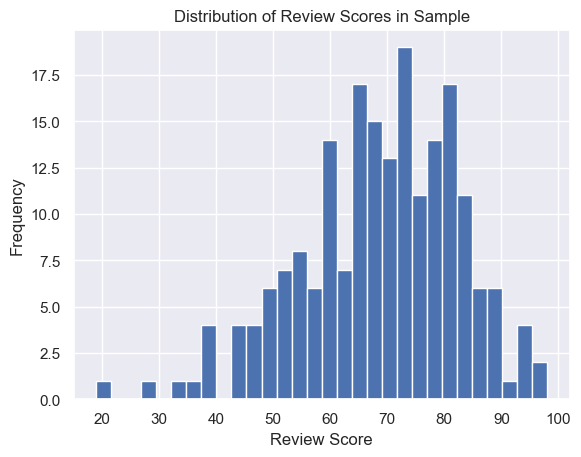

In [145]:
df_sample["Review Score"].hist(bins=30)
plt.xlabel("Review Score")
plt.ylabel("Frequency")
plt.title("Distribution of Review Scores in Sample")

The sample contains a random selection of 200 videogames, and I looked into the Review Scores variable. From the sample, I looked into the standard deviation, mean, min, q1, median, q3, and max values. The mean review score is 68.73, while the median review score is 70. The standard deviation is 13.26, meaning that the scores typically vary by 13.26 review points around the mean of 68.73. The minimum value is 28, the 25th percentile or Q1 is 61, the 75th percentile or Q3 is 79, and the maximum review score is 97. 

From the histogram, I see that our distribution is slightly left-skewed and bell-shaped, with most scores centered around the average. Since the data is skewed, it would be best to use the median as the measure of center to describe review scores since the median is less affected by skew than the mean is.

### Performing a Hypothesis Test

Although the median is the most appropriate measure of center for describing the slightly skewed sample distribution, I will test the population's mean since our large sample size of n=200 allows me to reliably estimate the mean due to the Central Limit Theorem (CLT). Since a sample of 200>30, CLT applies. This means that the sampling distribution of the mean will be approximately normal, though the sample data is skewed.

The parameter of interest is the true mean review score in our population of all video games released from 2004 to 2010. Next I will state the null and alternate hypothesis below.

Ho: μ = 70 (the true mean review score is equal to 70)

Ha: μ ≠ 70 (the true mean review score is not equal to 70)

I used a 2 sided alternative (μ ≠ 70) to see if the true mean review score of video games released between 2004 and 2010 differs from 70, a benchmark for an average game, without assuming a direction.

I will use a significance level of α = 0.05.

Before performing the hypothesis test, I will check the following conditions:

-Random: The sample was randomly selected, condition met

-Large sample: n=200>=30, so CLT applies, condition met

-Independence: The sample size of 200 is about 11.3% of the total population of 1770, which slightly exceeds the 10% condition. This means that my observations may not be fully independent, which is a limitation of this analysis.

In [146]:
observed_mean= df_sample["Review Score"].mean()
null_mean= 70

simulated_means= []
for i in range (5000):
    hyp_sample= df_sample["Review Score"].sample(n=200, replace=True)
    shifted_mean=hyp_sample.mean()-observed_mean+null_mean
    simulated_means.append(shifted_mean)
simulated_means=pd.DataFrame(simulated_means, columns=["means"])
simulated_means

,means
0,71.595
1,70.380
2,71.415
3,70.990
4,69.500
...,...
4995,69.575
4996,71.560
4997,70.725
4998,69.615


In [147]:
p_value=np.mean(np.abs(simulated_means["means"]-null_mean)>= np.abs(observed_mean-null_mean))
p_value

np.float64(0.1232)

Text(0.5, 1.0, 'Simulated Sampling Distribution Under Null Hypothesis')

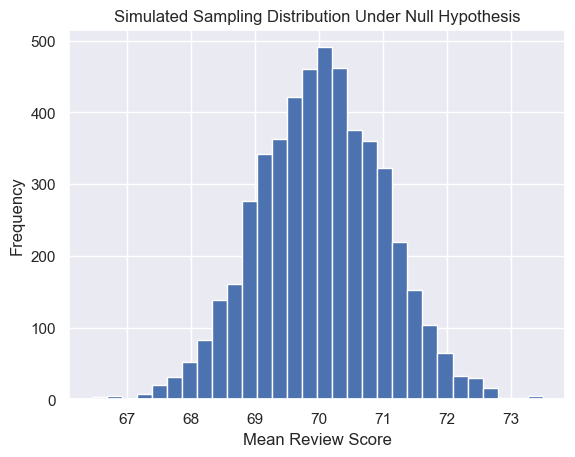

In [148]:
simulated_means["means"].hist(bins=30)
plt.xlabel("Mean Review Score")
plt.ylabel("Frequency")
plt.title("Simulated Sampling Distribution Under Null Hypothesis")

With a p-value of 0.8036 greater than the significance level of 0.05, I will fail to reject the null hypothesis. The data does not provide sufficient evidence that the true mean review score of video games released between 2004 and 2010 differs from 70.

A p-value of 0.8036 means that there is an 80.36% chance of observing a sample mean as extreme as 68.73 or more extreme purely by chance, assuming the null that the true mean review score is 70. This large p-value suggests that the observed sample mean is very consistent with the null hypothesis.

## Conclusion

Summary: For this report, I investigated two questions related to video game sequels and review scores for games released in the years 2004 to 2010. Using the first random sample of 200 video games, I examined the proportion of sequels in the sample and constructed a confidence interval to estimate the true population proportion. I am 95% confident that the true proportion of video games released between 2004 to 2010 that are sequels falls between 0.435 and 0.575. Additionally, I was able to conduct a one-sample hypothesis test to determine whether the true mean review score of all video games released between 2004 to 2010 equals the sample median of 70. Finally, with a p-value of 0.8036, which is well above any standard significance level (for this, I assumed alpha = 0.05), I failed to reject the null hypothesis. This means that there is insufficient evidence to conclude that the true mean review score is less than 70.
   

Limitations: One key limitation of this analysis is that the results are based on a random sample of 200 video games, meaning the sample changes every single time the code is run. This introduces variability and could slightly skew my estimates of both the proportion of sequels and the mean review score. Additionally, this dataset is restricted to games released between 2004 and 2010, so my findings may not generalize to video games released in other time periods, as industry trends, review standards, and sequel frequency have likely shifted over time. Whoever uses these results to make and interpret decisions about the video game industry should be cautious about applying these findings too broadly without accounting for how the market has evolved. 

# Video Game Analysis-Section 3: Predicting Video Game Value, A Regression Analysis of Used Prices and High-Price Classification

## Introduction
### Predicting Video Game Value: A Regression Analysis of Used Prices and High-Price Classification

### Dataset Introduction
This analysis uses the Video Games Dataset, which contains sales, pricing, and review information for over a thousand video games released between 2004 and 2010. The dataset includes variables such as used price, review scores, US sales figures, console platform, genre, and many more details.

### Response Variables
For the linear regression task, the response variable is Used Price (in dollars), a quantitative variable. For the logistic regression task, the response variable is High Price, a logical variable equal to 1 if a game's used price is above the median and 0 if not.

### Contextual Importance
Understanding what drives used video game prices is valuable for retailers, resellers, and consumers. A retailer like GameStop or an online reseller could use these models to price used inventory more accurately and avoid underpricing high-value games or overpricing ones unlikely to sell. Additionally, a consumer looking to resell their games could use review scores and sales data to estimate how much their game might fetch on the used market.

In [149]:
df

,Console,Title,US Sales (millions),Block4,Block2,Block1,Block0.5,YearReleased,2004,2005,...,Tricks,Volleyball,Wakeboarding,Wrestling,FirstPerson,Platform,Isometric,SideScrolling,TopDown,ThirdPerson
0,Nintendo DS,Super Mario 64 DS,4.69,1,1,1,1,2004,1,0,...,0,0,0,0,0,1,0,0,0,1
1,Sony PSP,Lumines: Puzzle Fusion,0.56,0,0,0,1,2004,1,0,...,0,0,0,0,0,0,0,0,0,0
2,Nintendo DS,WarioWare Touched!,0.54,0,0,0,1,2004,1,0,...,0,0,0,0,0,1,1,1,1,1
3,Sony PSP,Hot Shots Golf: Open Tee,0.49,0,0,0,0,2004,1,0,...,0,0,0,0,0,0,0,0,0,1
4,Nintendo DS,Spider-Man 2,0.45,0,0,0,0,2004,1,0,...,0,0,0,0,0,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1765,PlayStation 3,MotoGP 09/10,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,1,0,0,0,0,1
1766,PlayStation 3,Prison Break: The Conspiracy,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1767,Nintendo Wii,"Sakura Wars: So Long, My Love",0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,0,0,0,1
1768,X360,Record of Agarest War (The Really Naughty Limi...,0.04,0,0,0,0,2010,0,0,...,0,0,0,0,0,0,1,0,0,0


## Linear Regression Analytical Tasks

### Research Question:
What is the relationship between Used Price and Review Score after controlling for Year Released, US Sales (millions), and Console (PS2, Wii, X360, NDS), both in the sample and in the underlying population? How does my model perform on new data?

### Train Test Split & Fitting Linear Regression Model

In [150]:
df = df.rename(columns={'Review Score': 'Review_Score', 'US Sales (millions)': 'US_Sales'})

In [151]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size = 0.20, random_state = 406)

In [152]:
model_linear= smf.ols('Usedprice ~ Review_Score + YearReleased + US_Sales + PS2 + Wii + X360 + NDS', data=df_train).fit()
model_linear.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              Usedprice   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.314
Method:                 Least Squares   F-statistic:                     108.8
Date:                Tue, 07 Jul 2026   Prob (F-statistic):          9.11e-113
Time:                        00:07:11   Log-Likelihood:                -4658.7
No. Observations:                1416   AIC:                             9331.
Df Residuals:                    1409   BIC:                             9368.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    -5497.2593    263.688    -20.848      0.000   -6014.523   -4979.996
Review_Score     0.1008      0.014      7.430      0.000       0.074       0.127
YearReleased     2.7446      0.131     20.888      0.000       2.487       3.002
US_Sales         1.4827      0.213      6.975      0.000       1.066       1.900
PS2          -8.077e-17   2.36e-16     -0.343      0.732   -5.43e-16    3.81e-16
Wii              0.3554      0.520      0.683      0.494      -0.665       1.376
X360            -1.1822      0.465     -2.545      0.011      -2.093      -0.271
NDS             -0.2364      0.466     -0.508      0.612      -1.150       0.677
==============================================================================
Omnibus:                     1107.214   Durbin-Watson:                   2.031
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            67447.216
Skew:                           3.106   Prob(JB):                         0.00
Kurtosis:                      36.235   Cond. No.                     3.60e+20
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 4.41e-32. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

ŷ(UsedPrice)= -5497.26 +0.1008(Review_Score) +2.7446(YearReleased) +1.4827(US_Sales) -8.077e-17(PS2) +0.3554(Wii) -1.1822(X360) -0.2364(NDS)

### Relationship Between Used Price and Review Score

In this sample, for every one point increase in Review Score, Used Price is expected to increase by $0.1008, after controlling for Year Released, US Sales, PS2, Wii, X360, and NDS

In [153]:
model_linear.conf_int(alpha=0.05)

,0,1
Intercept,-6.014523e+03,-4.979996e+03
Review_Score,7.421790e-02,1.274613e-01
YearReleased,2.486861e+00,3.002368e+00
US_Sales,1.065656e+00,1.899682e+00
PS2,-5.429679e-16,3.814225e-16
Wii,-6.647924e-01,1.375568e+00
X360,-2.093461e+00,-2.708703e-01
NDS,-1.149886e+00,6.771575e-01


I am 95% confident that in the underlying population, for every one point increase in Review Score, Used Price increases between $0.074 and $0.127, controlling for all other variables. Since the interval does not contain 0, I have evidence of a positive relationship in the population.

In [154]:
fitted = model_linear.fittedvalues
residuals = model_linear.resid
residuals

964    -7.685186
829     0.506364
1429   -0.651496
454     2.988058
1756    2.382856
          ...   
671    -2.998501
432     3.100210
606    -9.819704
701    -2.610732
243    -8.877680
Length: 1416, dtype: float64

#### Graphical Summaries & Interpretations

Text(0.5, 1.0, 'Residuals vs Fitted')

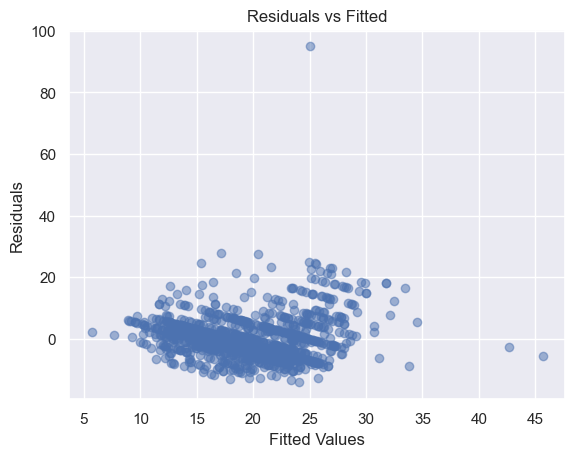

In [155]:
plt.scatter(fitted, residuals, alpha=0.5)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')

The residuals vs fitted plot shows that the points are not randomly scattered around 0, there appears to be several extreme outliers. This suggests that the linearity and equal variance conditions may not be fully met.

Text(0.5, 1.0, 'QQ Plot of Residuals')

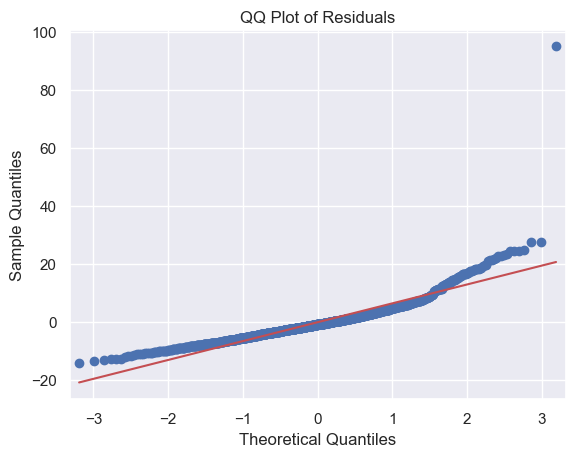

In [156]:
sm.qqplot(residuals, line='s')
plt.title('QQ Plot of Residuals')

The QQ plot shows deviation from the diagonal line, particularly in the tails. This indicates that the residuals are not normally distributed, meaning the normality condition may be violated.

Text(0.5, 1.0, 'Histogram of Residuals')

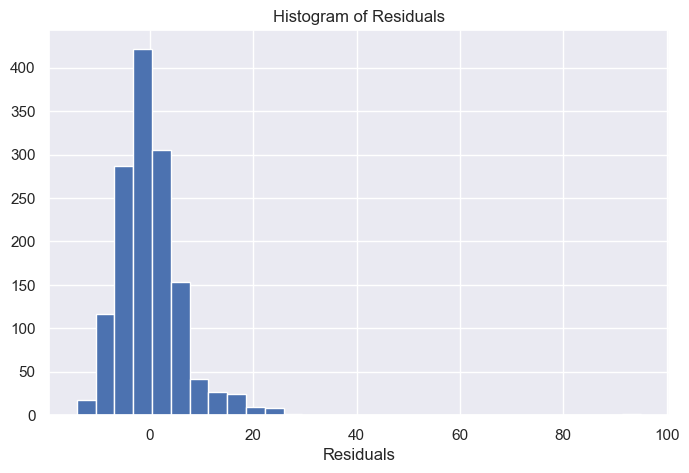

In [157]:
plt.figure(figsize=(8,5))
plt.hist(residuals, bins=30)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals')

The histogram of residuals is heavily right skewed and not bell-shaped, further confirming that the normality condition is not met.

Overall, these graphical summaries suggest that the normality and equal variance conditions are not met, most likely due to extreme outliers in the data. This means my interpretation of the slope coefficient is still valid, however the inference results such as the confidence interval and p-values should be interpreted with caution, as they rely on the normality assumption being met.

### Evaluating Model Performance

In [158]:
print(f"R-squared: {model_linear.rsquared:.4f}")

R-squared: 0.3165


Since the r-squared value is 0.3165, this model explains 31.65% of the variability for Used Price in the training data. This is relatively low, suggesting that other factors not included in the model also play a role in determining Used Price.

In [159]:
predictions = model_linear.predict(df_test)
rmse = np.sqrt(mean_squared_error(df_test['Usedprice'], predictions))
print(f"RMSE (test): {rmse:.4f}")

RMSE (test): 6.8409


In [160]:
df_test['Usedprice'].mean()

np.float64(19.825706214689262)

In [161]:
6.8409 / 19.8257 * 100

34.50521293069097

The RMSE on the test data is 6.84, which means that on average our model's predictions of Used Price are off by about $6.84. The average Used Price in the test data is $19.83, so an error of $6.84 is about 34.5% of the average Used Price. This is relatively high, suggesting the model does not predict Used Price properly on new data.

## Logistic Regression Analytical Tasks

### Research Question:
How do Review Score, US Sales (millions), and YearReleased relate to the log-odds of a video game having a high used price in the training sample? How does a classifier built from this model perform on unseen test data?

### Fit a Logistic Model

In [162]:
median_price = df['Usedprice'].median()
df['High_Price'] = (df['Usedprice'] > median_price).astype(int)
df_train2, df_test2 = train_test_split(df, test_size=0.2, random_state=406)

/var/folders/0j/7d9623r924z6zt5nn8xjwksc0000gn/T/ipykernel_60317/4272007614.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['High_Price'] = (df['Usedprice'] > median_price).astype(int)


In [163]:
model_logit = smf.logit('High_Price ~ Review_Score + US_Sales + YearReleased',data=df_train2).fit()
model_logit.summary()

Optimization terminated successfully.
         Current function value: 0.490170
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:             High_Price   No. Observations:                 1416
Model:                          Logit   Df Residuals:                     1412
Method:                           MLE   Df Model:                            3
Date:                Tue, 07 Jul 2026   Pseudo R-squ.:                  0.2068
Time:                        00:07:11   Log-Likelihood:                -694.08
converged:                       True   LL-Null:                       -875.07
Covariance Type:            nonrobust   LLR p-value:                 3.795e-78
================================================================================
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    -1737.2664    120.187    -14.455      0.000   -1972.828   -1501.705
Review_Score     0.0246      0.005      4.580      0.000       0.014       0.035
US_Sales         0.4689      0.102      4.593      0.000       0.269       0.669
YearReleased     0.8640      0.060     14.434      0.000       0.747       0.981
================================================================================
"""

Interpretation of Coefficients

Review_Score:
It is a positive coefficient. Higher review scores are associated with higher odds of a high used price.

US_Sales:
It is a positive coefficient. Higher U.S. sales are associated with higher odds of a high used price.

YearReleased:
It is a positive coefficient. Games released in later years are associated with higher odds of having a high used price.

In [164]:
print(f"Pseudo R-squared: {model_logit.prsquared:.4f}")

from sklearn.metrics import roc_auc_score
probs = model_logit.predict(df_test2)
auc = roc_auc_score(df_test2['High_Price'], probs)
print(f"AUC: {auc:.4f}")

Pseudo R-squared: 0.2068
AUC: 0.7688


Interpretation:

The Pseudo R-squared of 0.2068 indicates a moderate fit. Unlike regular R-squared, it does not explain variability. A value of 0.2068 suggests the model is a moderate improvement over a null model with no predictors.

The AUC of 0.7688 indicates that the model has a 76.88% chance of correctly distinguishing between a high and low used price game. This is considered a fairly good level of discriminatory ability.

### Build and Evaluate a Classifier

In [165]:
test_probs = model_logit.predict(df_test2)
test_preds = (test_probs >= 0.5).astype(int)
y_true = df_test2['High_Price'].values

In [166]:
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_true, test_preds)
TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_true, test_preds)
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

print(f"TP: {TP}, FN: {FN}, TN: {TN}, FP: {FP}")
print(f"Accuracy:    {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

TP: 65, FN: 57, TN: 206, FP: 26
Accuracy:    0.7655
Sensitivity: 0.5328
Specificity: 0.8879


In [167]:
cm_df = pd.DataFrame(cm,
                     index=['Actual: Low Price', 'Actual: High Price'],
                     columns=['Predicted: Low Price', 'Predicted: High Price'])
print(cm_df)

                    Predicted: Low Price  Predicted: High Price
Actual: Low Price                    206                     26
Actual: High Price                    57                     65


I want to minimize False Negatives (FN). In context, False Negative is when the model predicts low used price but the game is actually having a high used price. This would cause a retailer to underprice valuable games, losing potential revenue. To minimize false negatives, I want to maximize the sensitivity.

The classifier has an accuracy of 76.55%, specificity of 88.79%, and sensitivity of 53.28%. Since my goal is to minimize false negatives, the low sensitivity of 53.28% is a bit concerning since the model only correctly identifies about half of actual high-priced games. Therefore I am not fully satisfied with the classifier's performance, and a lower threshold below 0.5 could be explored to improve sensitivity.

## Conclusion

### Summary
In this project, I investigated what factors influence the used price of video games using both linear and logistic regression. For the linear regression task, I modeled Used Price as a function of Review Score, Year Released, US Sales, and console dummy variables (PS2, Wii, X360, NDS). I found a statistically significant positive relationship between Review Score and Used Price: for every one-point increase in Review Score, Used Price is expected to increase by approximately $0.10, controlling for all other variables. However, the model explained only 31.65% of the variance in Used Price (R^2 = 0.3165), and produced a test RMSE of $6.84, suggesting limited predictive power on new data. For our logistic regression task, I classified video games as having a "high" or "low" used price (relative to the median) using Review Score, US Sales, and Year Released as predictors. All three predictors had positive coefficients, indicating that higher review scores, greater US sales, and more recent release years are each associated with higher odds of a high used price. The model achieved an AUC of 0.7688 and a classification accuracy of 76.55%, though sensitivity was low at 53.28%, meaning it correctly identified only about half of the actual high-priced games. 

### Limitations

Several limitations affect this analysis and the conclusions that can be drawn from it. 

First, the linear regression model violated key assumptions: the residuals vs. fitted plot showed non-random patterns and extreme outliers, the QQ plot showed departures in the tails, and the histogram of residuals was heavily right-skewed. Because the normality and equal-variance conditions were not fully met, the confidence intervals and p-values from the linear model should be interpreted with caution. 

Second, both models explain only a moderate portion of the variability in used price, as many other factors such as game genre, franchise popularity, physical vs. digital availability, and regional demand are not captured in this dataset. 

Third, the logistic classifier's low sensitivity (53.28%) means it misses nearly half of all high-priced games, which is a meaningful weakness if the goal is to avoid underpricing valuable inventory. A retailer or reseller relying on this model for example would likely lose revenue by mispricing games the model incorrectly classifies as low-value. 

Another factor is that the train-test split was done with a random fixed seed, so performance estimates reflect one particular partition of the data. Having cross-validation would provide a more stable and generalizable estimate of the model's performance.

Lastly, The dataset only covers 2004-2010, limiting the generalizability of findings to current gaming markets where digital distribution has significantly changed used game pricing.